Task 1: Temperature 

In [24]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from frost_id import client_id

client_id = client_id

#Requests the daily mean air temperture for all of 2025
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
data = r.json()


Make a nicely formatted plot of this air temperature, where time is on the x-axis and
temperature is on the y-axis


In [25]:
observations = data["data"]

df = pd.DataFrame(observations)

df.head()

df["temperature"] = df["observations"].apply(
    lambda x: x[0]["value"]
)

df["time"] = pd.to_datetime(df["referenceTime"])

df.head()

df["temperature"] = df["observations"].apply(
    lambda x: x[0]["value"]
)

df["time"] = pd.to_datetime(df["referenceTime"])

df.head()

,sourceId,referenceTime,observations,temperature,time
0,SN17850:0,2025-01-01T00:00:00.000Z,"[{'elementId': 'mean(air_temperature P1D)', 'v...",-5.2,2025-01-01 00:00:00+00:00
1,SN17850:0,2025-01-02T00:00:00.000Z,"[{'elementId': 'mean(air_temperature P1D)', 'v...",-11.5,2025-01-02 00:00:00+00:00
2,SN17850:0,2025-01-03T00:00:00.000Z,"[{'elementId': 'mean(air_temperature P1D)', 'v...",-8.9,2025-01-03 00:00:00+00:00
3,SN17850:0,2025-01-04T00:00:00.000Z,"[{'elementId': 'mean(air_temperature P1D)', 'v...",-15.5,2025-01-04 00:00:00+00:00
4,SN17850:0,2025-01-05T00:00:00.000Z,"[{'elementId': 'mean(air_temperature P1D)', 'v...",-12.5,2025-01-05 00:00:00+00:00


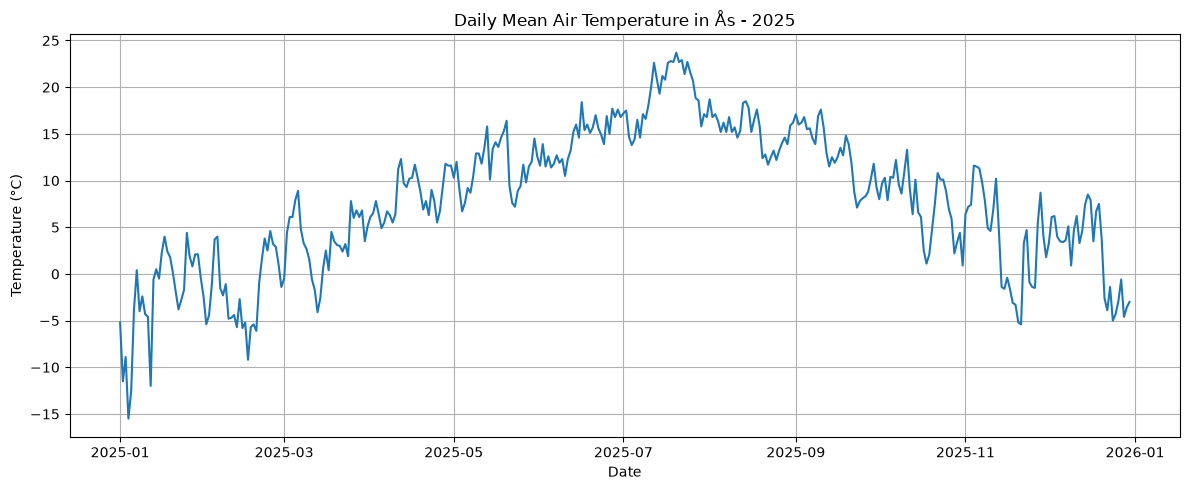

In [26]:

plt.figure(figsize=(12, 5))

plt.plot(df["time"], df["temperature"])

plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Daily Mean Air Temperature in Ås - 2025")

plt.grid(True)
plt.tight_layout()
plt.show()

Create a nicely formatted summary table containing mean, median, min and max
temperature for this year, and display it with print()

In [27]:
summary = {
    "Mean": df["temperature"].mean(),
    "Median": df["temperature"].median(),
    "Min": df["temperature"].min(),
    "Max": df["temperature"].max()
}

print(summary)

{'Mean': np.float64(7.902747252747254), 'Median': np.float64(8.4), 'Min': np.float64(-15.5), 'Max': np.float64(23.7)}


In [28]:
summary_table = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Min", "Max"],
    "Temperature (°C)": [
        df["temperature"].mean(),
        df["temperature"].median(),
        df["temperature"].min(),
        df["temperature"].max()
    ]
})

print(summary_table)

  Statistic  Temperature (°C)
0      Mean          7.902747
1    Median          8.400000
2       Min        -15.500000
3       Max         23.700000


Task 2: Combined graph

In [ ]:
#Requests the daily mean air temperture for all of 2025
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'sum(precipitation_amount P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, params=parameters, auth=(client_id,''))


# Extract JSON data for precipitation
precipitation_json = r.json()

#Precipitation to a Pandas dataframe 
precipitation_data = pd.DataFrame(precipitation_json["data"])

# Get the data from where it is placed in the data (in observations)
precipitation_data["precipitation"] = precipitation_data["observations"].apply(
    lambda x: x[0]["value"])

#Time converted to Datetime with pandas
precipitation_data["time"] = pd.to_datetime(precipitation_data["referenceTime"])


# Combining data before plotting. Refrences the data from the task 1
Combined_data = pd.merge(df[["time","temperature"]], precipitation_data[["time","precipitation"]], on="time")

print(Combined_data)


                         time  temperature  precipitation
0   2025-01-01 00:00:00+00:00         -5.2            5.4
1   2025-01-02 00:00:00+00:00        -11.5            0.0
2   2025-01-03 00:00:00+00:00         -8.9            0.1
3   2025-01-04 00:00:00+00:00        -15.5            0.0
4   2025-01-05 00:00:00+00:00        -12.5            0.5
..                        ...          ...            ...
359 2025-12-26 00:00:00+00:00         -2.9            0.1
360 2025-12-27 00:00:00+00:00         -0.6            0.0
361 2025-12-28 00:00:00+00:00         -4.6            0.0
362 2025-12-29 00:00:00+00:00         -3.6            0.0
363 2025-12-30 00:00:00+00:00         -3.0            0.0

[364 rows x 3 columns]


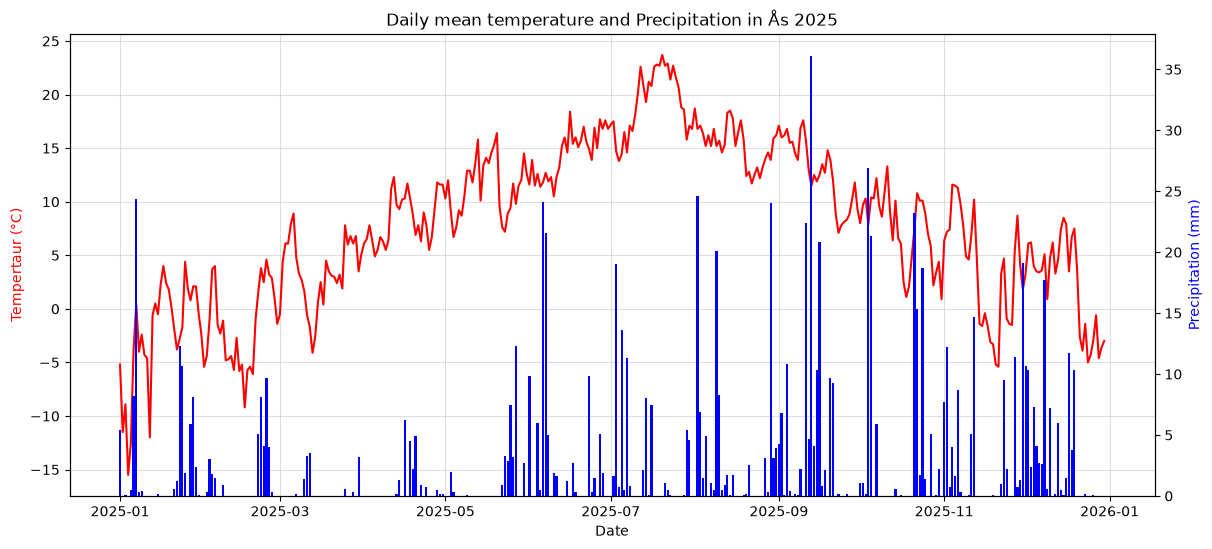

In [ ]:
#Plotting the data

# Creates a figure
fig, ax1 = plt.subplots(figsize=(14, 6))

#Plots temperature on the first axis
ax1.plot(Combined_data["time"],
         Combined_data["temperature"],
         color="red")

#Names the axises
ax1.set_xlabel("Date")
ax1.set_ylabel("Tempertaur (°C)", color="red")

# Creates a second axis for precipitation since it and temperature dont have the same scale
ax2 = ax1.twinx()

ax2.bar(Combined_data["time"],
        Combined_data["precipitation"],
        color="blue")

ax2.set_ylabel("Precipitation (mm)", color="blue")

# Adds a grid based on ax1
ax1.grid(True, alpha=0.4)
#Title on the graph
plt.title("Daily mean temperature and Precipitation in Ås 2025")

plt.show()

Task 3: Historical temperature data


Now you want to compare the 2025 temperatures to temperatures measured 100
years earlier.

Get these temperatures from the database.

Plot the new and the old temperatures in the same plot, still nicely formatted

Generate a summary table as for task 1, where you display data from both the new

and the old temperatures.

Part 1: Plot

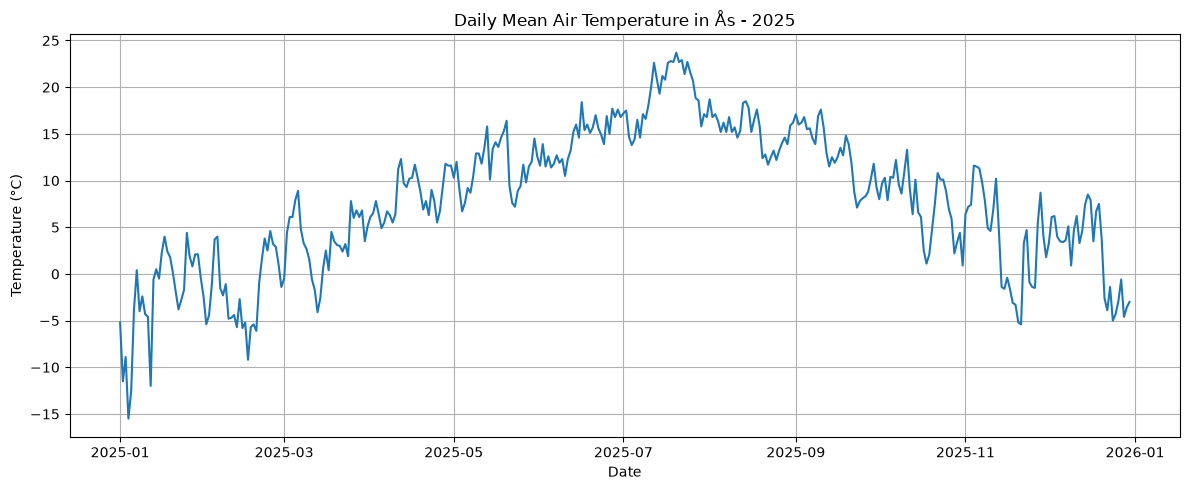

In [49]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from frost_id import client_id

client_id = client_id

#Requests the daily mean air temperture for all of 2025
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
data = r.json()

observations = data["data"]

df = pd.DataFrame(observations)



df["temperature"] = df["observations"].apply(
    lambda x: x[0]["value"]
)

df["time"] = pd.to_datetime(df["referenceTime"])



df["temperature"] = df["observations"].apply(
    lambda x: x[0]["value"]
)

df["time"] = pd.to_datetime(df["referenceTime"])

plt.figure(figsize=(12, 5))

plt.plot(df["time"], df["temperature"])

plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Daily Mean Air Temperature in Ås - 2025")

plt.grid(True)
plt.tight_layout()
plt.show()



Plot 2

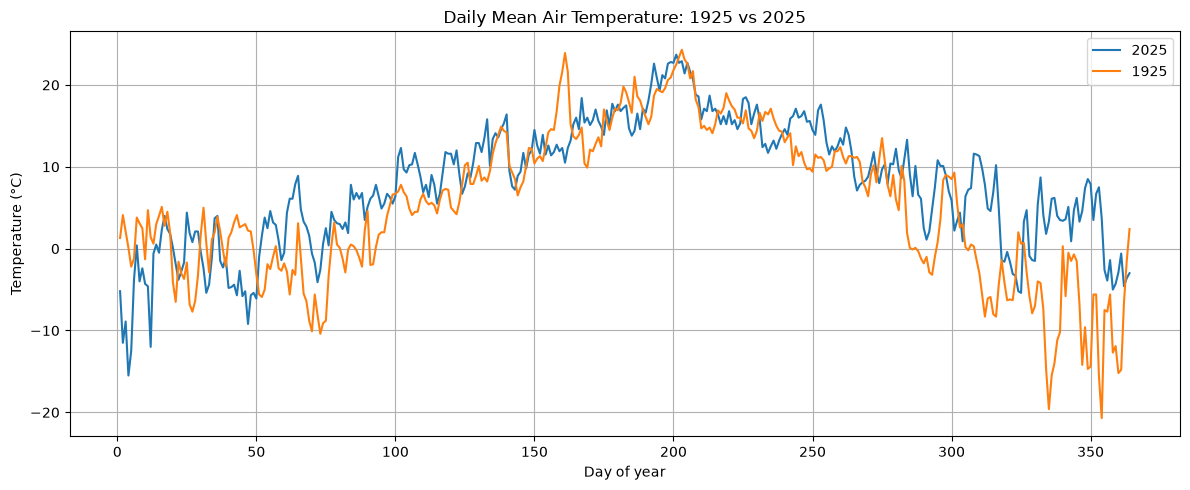

In [50]:
# Requests the daily mean air temperature for all of 1925
endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters_1925 = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '1925-01-01/1925-12-31',
}

# Issue an HTTP GET request
r_1925 = requests.get(
    endpoint,
    parameters_1925,
    auth=(client_id, '')
)

# Extract JSON data
data_1925 = r_1925.json()

observations_1925 = data_1925["data"]

df_1925 = pd.DataFrame(observations_1925)

df_1925["temperature"] = df_1925["observations"].apply(
    lambda x: x[0]["value"]
)

df_1925["time"] = pd.to_datetime(df_1925["referenceTime"])

df["day"] = df["time"].dt.dayofyear
df_1925["day"] = df_1925["time"].dt.dayofyear

# Create a new figure for the comparison plot
plt.figure(figsize=(12, 5))

plt.plot(
    df["day"],
    df["temperature"],
    label="2025"
)

plt.plot(
    df_1925["day"],
    df_1925["temperature"],
    label="1925"
)

plt.xlabel("Day of year")
plt.ylabel("Temperature (°C)")
plt.title("Daily Mean Air Temperature: 1925 vs 2025")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [51]:
#Tabell
summary_table = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Min", "Max"],
    "1925 (°C)": [
        df_1925["temperature"].mean(),
        df_1925["temperature"].median(),
        df_1925["temperature"].min(),
        df_1925["temperature"].max()
    ],
    "2025 (°C)": [
        df["temperature"].mean(),
        df["temperature"].median(),
        df["temperature"].min(),
        df["temperature"].max()
    ]
})

print(summary_table)

  Statistic  1925 (°C)  2025 (°C)
0      Mean    5.31044   7.902747
1    Median    5.30000   8.400000
2       Min  -20.70000 -15.500000
3       Max   24.30000  23.700000
